# Task 5: Stronger architectures and pre-trained models

**Objective:** increase validation accuracy (if possible) with
**(a)** more powerful architectures trained from scratch (ResNet, DenseNet), and
**(b)** pre-trained ImageNet models (VGG16, ResNet50) that are fine-tuned on this data.
Report accuracy *and* training/running time for each.

Adam Oakes

**Setup** (same pipeline as the Task 3 and Task 4 notebooks)
* Images load at their native 32×32 and are cached in memory. Every model upsamples them to
  180×180 inside the network, the same way as in Task 2.
* Same seed, batch size (64) and early-stopping rule as before.
* The Task 2 CNN is retrained here as the **anchor row**. With the same seed it should match
  the Task 3/4 baselines, which confirms that all three notebooks are measuring the same thing.

**Part (a): stronger architectures from scratch** (random weights)
* `mini_resnet`: residual blocks with BatchNorm, in the same size class as the Task 2 CNN (about
  2.4M vs 1.6M parameters), so a change in accuracy mostly reflects the *design* (skip connections),
  not size. It is slower per epoch, though: every block runs two convolutions at full resolution.
* `mini_densenet`: dense blocks, where each layer receives every earlier layer's output.
* `resnet50_scratch`: the full ResNet50 (about 24M parameters) with **random** weights.

**Part (b): pre-trained ImageNet models**, in two phases
1. **Feature extraction:** freeze the whole pre-trained base and train only a new classifier head.
2. **Fine-tuning:** start from phase 1, unfreeze the *top* block of the base, and keep training
   at a 100× lower learning rate (1e-5), so the pre-trained features are adjusted, not wiped out.

`resnet50_scratch` and the two `resnet50_imagenet` rows use the identical architecture,
input preprocessing and head. The only difference is whether the starting weights are random
or come from ImageNet, so comparing them isolates the value of pre-training.

**Timing:** every row records seconds per epoch, total training time, and the time to run the
whole validation set through the model (inference). Fine-tuning rows also report the
*cumulative* time of both phases.

# Library imports and configuration

In [1]:
import os, json, time, platform
from pathlib import Path

import keras
from keras import layers
from keras.utils import image_dataset_from_directory
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TASK = "task_5"
DATA_DIR = Path(os.environ.get("DATA_DIR", "../data"))
EPOCHS = int(os.environ.get("EPOCHS", 4))          # from-scratch models; same as Task 2
FE_EPOCHS = int(os.environ.get("FE_EPOCHS", 4))    # pre-trained, phase 1 (frozen base)
FT_EPOCHS = int(os.environ.get("FT_EPOCHS", 4))    # pre-trained, phase 2 (fine-tuning)
FT_LR = 1e-5                                       # fine-tuning learning rate
BATCH_SIZE = 64
NATIVE_SIZE = (32, 32)
MODEL_SIZE = (180, 180)
SEED = 42
PRETRAINED_WEIGHTS = os.environ.get("PRETRAINED_WEIGHTS", "imagenet")  # "imagenet" for the real run

# Comment out any model you want to skip (for example, if a machine is too slow).
RUN = [
    "task2_cnn",
    "mini_resnet",
    "mini_densenet",
    "resnet50_scratch",
    "vgg16_imagenet",          # runs both phases: feature extraction, then fine-tuning
    "resnet50_imagenet",       # runs both phases: feature extraction, then fine-tuning
]

OUT = Path(os.environ.get("OUT_DIR", ".."))
plots = OUT / "plots" / TASK
results_dir = OUT / "results" / TASK
ckpt_dir = OUT / "checkpoints" / TASK
for d in (plots, results_dir, ckpt_dir):
    d.mkdir(parents=True, exist_ok=True)
RESULTS_CSV = results_dir / "architecture_results.csv"
HISTORY_JSON = results_dir / "architecture_histories.json"

GPUS = tf.config.list_physical_devices("GPU")
MACHINE = f"{platform.node()} | {platform.machine()} | GPUs: {len(GPUS)}"
print(MACHINE)
print("results ->", RESULTS_CSV.resolve())

Raizen | x86_64 | GPUs: 1
results -> /home/adam/projects/Real_vs_Fake_Classifier/results/task_5/architecture_results.csv


**About timing across computers:** training times only mean something when they're measured on
the same machine. Each row records which machine it ran on (the `machine` column). Compare times
*within* this table, and don't compare them with Tasks 2–4 if those ran on a different computer.

# Load the data (native 32×32, cached in memory)

In [2]:
def load(split, shuffle):
    return image_dataset_from_directory(
        DATA_DIR / split, image_size=NATIVE_SIZE, batch_size=BATCH_SIZE,
        shuffle=shuffle, seed=SEED,
    )

train_dataset = load("train", shuffle=True)
validation_dataset = load("validation", shuffle=False)
print(train_dataset.class_names)

train_ds = (train_dataset.unbatch().cache()
            .shuffle(20_000, seed=SEED, reshuffle_each_iteration=True)
            .batch(BATCH_SIZE).prefetch(tf.data.AUTOTUNE))
val_ds = validation_dataset.cache().prefetch(tf.data.AUTOTUNE)

Found 80000 files belonging to 2 classes.
Found 20000 files belonging to 2 classes.
['FAKE', 'REAL']


# Part (a): architectures trained from scratch

In [3]:
def upsampled_input():
    inputs = keras.Input(shape=NATIVE_SIZE + (3,))
    x = layers.Resizing(*MODEL_SIZE, interpolation="bilinear")(inputs)   # same 32->180 upsample as Task 2
    return inputs, x

def task2_cnn():
    # The Task 2 best model, unchanged: the anchor row
    inputs, x = upsampled_input()
    x = layers.Rescaling(1.0 / 255)(x)
    for f in [32, 64, 128, 256]:
        x = layers.Conv2D(f, 3, activation="relu")(x)
        x = layers.MaxPooling2D(2)(x)
    x = layers.Conv2D(512, 3, activation="relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="task2_cnn")

def residual_block(x, filters, pooling):
    # Two 3x3 convs, plus a shortcut that skips over them. The block only has to learn a
    # *correction* to its input; this keeps gradients flowing through deep stacks.
    shortcut = x
    for _ in range(2):
        x = layers.Conv2D(filters, 3, padding="same", use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
    if pooling:
        x = layers.MaxPooling2D(2, padding="same")(x)
        shortcut = layers.Conv2D(filters, 1, strides=2)(shortcut)   # match the new shape
    elif shortcut.shape[-1] != filters:
        shortcut = layers.Conv2D(filters, 1)(shortcut)
    return layers.add([x, shortcut])

def mini_resnet():
    inputs, x = upsampled_input()
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    for f in [32, 64, 128, 256]:
        x = residual_block(x, f, pooling=True)
    x = residual_block(x, 256, pooling=False)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="mini_resnet")

def dense_block(x, n_layers, growth):
    # Each layer sees the concatenation of ALL previous layers' outputs (feature reuse),
    # and adds `growth` new channels to the stack.
    for _ in range(n_layers):
        y = layers.BatchNormalization()(x)
        y = layers.Activation("relu")(y)
        y = layers.Conv2D(4 * growth, 1, use_bias=False)(y)      # bottleneck
        y = layers.BatchNormalization()(y)
        y = layers.Activation("relu")(y)
        y = layers.Conv2D(growth, 3, padding="same", use_bias=False)(y)
        x = layers.Concatenate()([x, y])
    return x

def transition(x):
    # Halve the channels (compression) and the spatial size between dense blocks
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.Conv2D(x.shape[-1] // 2, 1, use_bias=False)(x)
    return layers.AveragePooling2D(2)(x)

def mini_densenet(growth=24, blocks=(4, 6, 8, 6)):
    inputs, x = upsampled_input()
    x = layers.Rescaling(1.0 / 255)(x)
    x = layers.Conv2D(2 * growth, 3, strides=2, padding="same", use_bias=False)(x)   # 180 -> 90
    x = layers.MaxPooling2D(2)(x)                                                    # 90 -> 45
    for i, n in enumerate(blocks):
        x = dense_block(x, n, growth)
        if i < len(blocks) - 1:
            x = transition(x)
    x = layers.BatchNormalization()(x)
    x = layers.Activation("relu")(x)
    x = layers.GlobalAveragePooling2D()(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    return keras.Model(inputs, outputs, name="mini_densenet")

# Part (b): pre-trained base + new head

Both VGG16 and ResNet50 were trained on ImageNet with "caffe" preprocessing (RGB→BGR plus
mean subtraction). The images must be fed the same way, or the pre-trained filters see inputs
they were never trained on. `resnet50_scratch` uses the same preprocessing, so the scratch vs
pre-trained comparison changes *only* the starting weights.

The base is always called with `training=False`. For ResNet50 this keeps its BatchNorm layers
using their ImageNet statistics, even after unfreezing. Otherwise the first fine-tuning batches
would overwrite those statistics and wreck the pre-trained features.

In [4]:
BASES = {
    # name: (constructor, preprocess fn, name prefix of the top block to unfreeze when fine-tuning)
    "vgg16":    (keras.applications.VGG16,    keras.applications.vgg16.preprocess_input,    "block5_"),
    "resnet50": (keras.applications.ResNet50, keras.applications.resnet50.preprocess_input, "conv5_"),
}

def pretrained_model(base_name, weights):
    make, preprocess, _ = BASES[base_name]
    base = make(weights=weights, include_top=False, input_shape=MODEL_SIZE + (3,))
    inputs, x = upsampled_input()
    x = layers.Lambda(preprocess, name="preprocess")(x)
    x = base(x, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.5)(x)
    outputs = layers.Dense(1, activation="sigmoid")(x)
    model = keras.Model(inputs, outputs, name=f"{base_name}_{weights or 'scratch'}")
    return model, base

def set_trainable(base, mode, top_prefix=None):
    # mode: "all" | "none" | "top" (only layers whose name starts with top_prefix)
    base.trainable = mode != "none"
    if mode == "top":
        for layer in base.layers:
            layer.trainable = layer.name.startswith(top_prefix)

def count_trainable(model):
    return int(sum(np.prod(w.shape) for w in model.trainable_weights))

# Training loop

Every configuration is timed. Results go to a CSV **after each row**, and the phase-1 weights
of the pre-trained models are saved to `checkpoints/task_5/`. If the kernel dies, re-running
the cell skips finished rows, and fine-tuning resumes from the saved phase-1 weights.

In [5]:
class EpochTimer(keras.callbacks.Callback):
    def on_train_begin(self, logs=None): self.times = []
    def on_epoch_begin(self, epoch, logs=None): self.t0 = time.time()
    def on_epoch_end(self, epoch, logs=None): self.times.append(time.time() - self.t0)

def load_results():
    return pd.read_csv(RESULTS_CSV) if RESULTS_CSV.exists() else pd.DataFrame()

def is_done(name):
    r = load_results()
    return len(r) and name in set(r["config"])

def fit_and_record(model, name, part, method, epochs, lr, prior_sec=0.0, prior_epochs=0):
    model.compile(loss="binary_crossentropy", metrics=["accuracy"],
                  optimizer=keras.optimizers.Adam(learning_rate=lr))
    timer = EpochTimer()
    cb = [timer, keras.callbacks.EarlyStopping(monitor="val_accuracy", patience=3,
                                               mode="max", restore_best_weights=True)]
    t0 = time.time()
    h = model.fit(train_ds, epochs=epochs, validation_data=val_ds, callbacks=cb, verbose=2)
    train_sec = time.time() - t0
    t1 = time.time()
    model.evaluate(val_ds, verbose=0)                 # inference time over the 20k validation images
    infer_sec = time.time() - t1

    hist = {k: [float(v) for v in vals] for k, vals in h.history.items()}
    best = int(np.argmax(hist["val_accuracy"]))
    n_ep = len(hist["accuracy"])
    row = dict(
        config=name, part=part, method=method, machine=MACHINE,
        total_params=model.count_params(), trainable_params=count_trainable(model),
        best_val_acc=hist["val_accuracy"][best], best_epoch=best + 1,
        final_train_acc=hist["accuracy"][-1], final_val_acc=hist["val_accuracy"][-1],
        epochs_run=n_ep, sec_per_epoch=float(np.median(timer.times)),
        first_epoch_sec=timer.times[0], train_sec=train_sec,
        cumulative_epochs=prior_epochs + n_ep, cumulative_train_sec=prior_sec + train_sec,
        val_inference_sec=infer_sec,
    )
    pd.concat([load_results(), pd.DataFrame([row])], ignore_index=True).to_csv(RESULTS_CSV, index=False)
    hs = json.loads(HISTORY_JSON.read_text()) if HISTORY_JSON.exists() else {}
    hs[name] = hist
    HISTORY_JSON.write_text(json.dumps(hs))
    print(f"==> {name}: best val_acc {row['best_val_acc']:.4f} | "
          f"{row['sec_per_epoch']:.0f} s/epoch | {train_sec/60:.1f} min total")
    return row

SCRATCH = {"task2_cnn": task2_cnn, "mini_resnet": mini_resnet, "mini_densenet": mini_densenet}

import gc
for name in RUN:
    keras.backend.clear_session()   # free the previous model's memory before building the next one
    gc.collect()
    if name in SCRATCH:
        if is_done(name): print(f"skip {name}"); continue
        keras.utils.set_random_seed(SEED)
        method = "baseline (Task 2 CNN)" if name == "task2_cnn" else "from scratch"
        fit_and_record(SCRATCH[name](), name, "a", method, EPOCHS, 1e-3)

    elif name == "resnet50_scratch":
        if is_done(name): print(f"skip {name}"); continue
        keras.utils.set_random_seed(SEED)
        model, base = pretrained_model("resnet50", None)
        set_trainable(base, "all")
        fit_and_record(model, name, "a", "from scratch (random weights)", EPOCHS, 1e-3)

    elif name.endswith("_imagenet"):
        base_name = name.split("_")[0]
        fe_name, ft_name = f"{name}_feature_extract", f"{name}_fine_tune"
        fe_weights = ckpt_dir / f"{fe_name}.weights.h5"

        keras.utils.set_random_seed(SEED)
        model, base = pretrained_model(base_name, PRETRAINED_WEIGHTS)

        # Phase 1: frozen base, train only the head
        if not is_done(fe_name):
            set_trainable(base, "none")
            fit_and_record(model, fe_name, "b", "pre-trained, frozen base (feature extraction)",
                           FE_EPOCHS, 1e-3)
            model.save_weights(fe_weights)
        else:
            print(f"skip {fe_name}")

        # Phase 2: unfreeze the top block, low learning rate
        if not is_done(ft_name):
            set_trainable(base, "none")                # match phase-1 layout, then load its weights
            model.load_weights(fe_weights)
            set_trainable(base, "top", BASES[base_name][2])
            prev = load_results().set_index("config").loc[fe_name]
            fit_and_record(model, ft_name, "b",
                           f"pre-trained, fine-tune top block ({BASES[base_name][2]}*), lr={FT_LR:g}",
                           FT_EPOCHS, FT_LR,
                           prior_sec=float(prev.train_sec), prior_epochs=int(prev.epochs_run))
        else:
            print(f"skip {ft_name}")

Epoch 1/4


/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 52s - 42ms/step - accuracy: 0.8058 - loss: 0.4221 - val_accuracy: 0.8849 - val_loss: 0.2792
Epoch 2/4
1250/1250 - 36s - 29ms/step - accuracy: 0.8878 - loss: 0.2716 - val_accuracy: 0.8888 - val_loss: 0.2813
Epoch 3/4
1250/1250 - 36s - 29ms/step - accuracy: 0.9088 - loss: 0.2266 - val_accuracy: 0.8957 - val_loss: 0.2507
Epoch 4/4
1250/1250 - 36s - 29ms/step - accuracy: 0.9185 - loss: 0.2039 - val_accuracy: 0.9244 - val_loss: 0.1897
==> task2_cnn: best val_acc 0.9244 | 36 s/epoch | 2.7 min total
Epoch 1/4


/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 167s - 134ms/step - accuracy: 0.8735 - loss: 0.2967 - val_accuracy: 0.8680 - val_loss: 0.3601
Epoch 2/4
1250/1250 - 131s - 105ms/step - accuracy: 0.9284 - loss: 0.1815 - val_accuracy: 0.9428 - val_loss: 0.1507
Epoch 3/4
1250/1250 - 131s - 105ms/step - accuracy: 0.9377 - loss: 0.1618 - val_accuracy: 0.9342 - val_loss: 0.1716
Epoch 4/4
1250/1250 - 131s - 105ms/step - accuracy: 0.9429 - loss: 0.1478 - val_accuracy: 0.9208 - val_loss: 0.1997
==> mini_resnet: best val_acc 0.9428 | 131 s/epoch | 9.3 min total
Epoch 1/4


/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


... (7 outputs left out)

/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 52s - 42ms/step - accuracy: 0.8540 - loss: 0.3327 - val_accuracy: 0.8910 - val_loss: 0.2562
Epoch 2/4
1250/1250 - 41s - 33ms/step - accuracy: 0.8824 - loss: 0.2785 - val_accuracy: 0.9218 - val_loss: 0.1993
Epoch 3/4
1250/1250 - 40s - 32ms/step - accuracy: 0.8826 - loss: 0.2806 - val_accuracy: 0.9202 - val_loss: 0.2003
Epoch 4/4
1250/1250 - 39s - 31ms/step - accuracy: 0.8830 - loss: 0.2782 - val_accuracy: 0.9176 - val_loss: 0.2051
==> resnet50_imagenet_feature_extract: best val_acc 0.9218 | 41 s/epoch | 2.9 min total
Epoch 1/4


/home/adam/.virtualenvs/dl/lib/python3.10/site-packages/keras/src/trainers/epoch_iterator.py:164: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


1250/1250 - 68s - 55ms/step - accuracy: 0.9220 - loss: 0.2033 - val_accuracy: 0.9600 - val_loss: 0.1043
Epoch 2/4
1250/1250 - 51s - 41ms/step - accuracy: 0.9629 - loss: 0.0966 - val_accuracy: 0.9686 - val_loss: 0.0854
Epoch 3/4
1250/1250 - 49s - 39ms/step - accuracy: 0.9794 - loss: 0.0544 - val_accuracy: 0.9720 - val_loss: 0.0799
Epoch 4/4
1250/1250 - 50s - 40ms/step - accuracy: 0.9888 - loss: 0.0309 - val_accuracy: 0.9733 - val_loss: 0.0808
==> resnet50_imagenet_fine_tune: best val_acc 0.9733 | 51 s/epoch | 3.6 min total


# Results table

In [6]:
res = load_results()
base_acc = res.loc[res.config == "task2_cnn", "best_val_acc"].item() if "task2_cnn" in set(res.config) else np.nan
res["delta_vs_task2"] = res.best_val_acc - base_acc
cols = ["part", "config", "method", "total_params", "trainable_params", "best_val_acc",
        "delta_vs_task2", "cumulative_epochs", "sec_per_epoch", "cumulative_train_sec", "val_inference_sec"]
table = res[cols].copy()

def to_markdown(df):
    fmt = {"total_params": "{:,}", "trainable_params": "{:,}", "best_val_acc": "{:.4f}",
           "delta_vs_task2": "{:+.4f}", "sec_per_epoch": "{:.0f}",
           "cumulative_train_sec": "{:.0f}", "val_inference_sec": "{:.1f}"}
    lines = ["| " + " | ".join(df.columns) + " |", "|" + "---|" * len(df.columns)]
    for _, r in df.iterrows():
        lines.append("| " + " | ".join(fmt.get(c, "{}").format(r[c]) for c in df.columns) + " |")
    return "\n".join(lines)

md_table = to_markdown(table)
(results_dir / "architecture_results.md").write_text(md_table)
from IPython.display import Markdown, display
display(Markdown(md_table))
print("Measured on:", res.machine.unique())

| part | config | method | total_params | trainable_params | best_val_acc | delta_vs_task2 | cumulative_epochs | sec_per_epoch | cumulative_train_sec | val_inference_sec |
|---|---|---|---|---|---|---|---|---|---|---|
| a | task2_cnn | baseline (Task 2 CNN) | 1,569,089 | 1,569,089 | 0.9244 | +0.0000 | 4 | 36 | 160 | 2.2 |
| a | mini_resnet | from scratch | 2,410,945 | 2,407,937 | 0.9428 | +0.0184 | 4 | 131 | 560 | 7.0 |
| a | mini_densenet | from scratch | 983,383 | 969,019 | 0.9418 | +0.0174 | 4 | 45 | 240 | 3.6 |
| a | resnet50_scratch | from scratch (random weights) | 23,589,761 | 23,536,641 | 0.9169 | -0.0075 | 4 | 121 | 535 | 8.5 |
| b | vgg16_imagenet_feature_extract | pre-trained, frozen base (feature extraction) | 14,715,201 | 513 | 0.8623 | -0.0621 | 4 | 84 | 344 | 15.8 |
| b | vgg16_imagenet_fine_tune | pre-trained, fine-tune top block (block5_*), lr=1e-05 | 14,715,201 | 7,079,937 | 0.9659 | +0.0415 | 8 | 92 | 719 | 15.9 |
| b | resnet50_imagenet_feature_extract | pre-trained, frozen base (feature extraction) | 23,589,761 | 2,049 | 0.9218 | -0.0027 | 4 | 41 | 173 | 8.4 |
| b | resnet50_imagenet_fine_tune | pre-trained, fine-tune top block (conv5_*), lr=1e-05 | 23,589,761 | 14,978,049 | 0.9733 | +0.0488 | 8 | 51 | 392 | 7.1 |

Measured on: ['Raizen | x86_64 | GPUs: 1']


# Plots

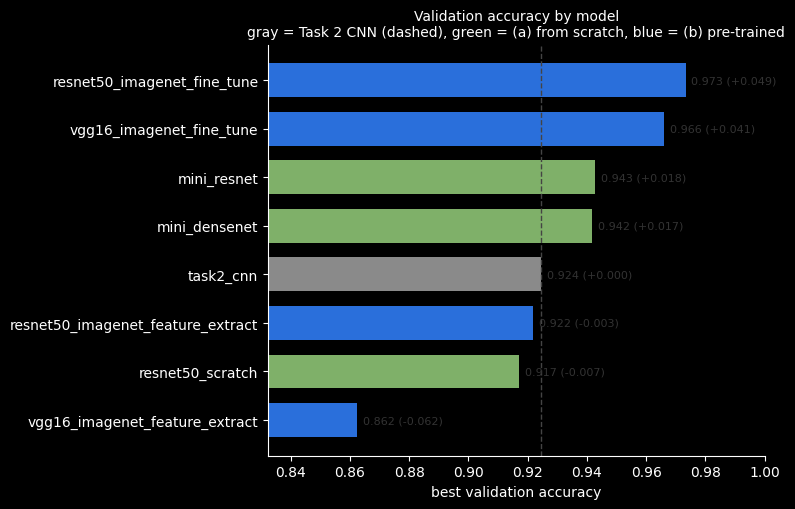

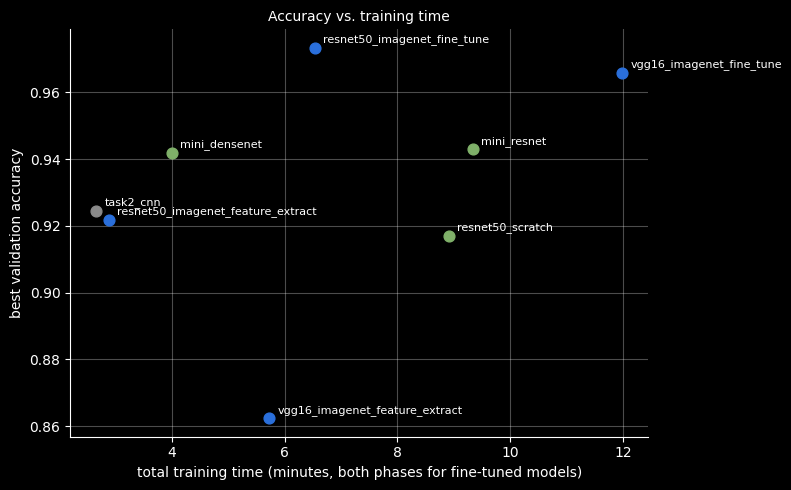

In [7]:
# 1) Validation accuracy per model
t = res.sort_values("best_val_acc")
colors = ["#8a8a8a" if c == "task2_cnn" else ("#2a6fdb" if p == "b" else "#7fb069")
          for c, p in zip(t.config, t.part)]
fig, ax = plt.subplots(figsize=(8, 0.5 * len(t) + 1.2))
ax.barh(t.config, t.best_val_acc, color=colors, height=0.7)
if not np.isnan(base_acc):
    ax.axvline(base_acc, color="#444", lw=1, ls="--")
for y, (v, d) in enumerate(zip(t.best_val_acc, t.delta_vs_task2)):
    ax.text(v + 0.002, y, f"{v:.3f} ({d:+.3f})", va="center", fontsize=8, color="#333")
ax.set_xlim(max(0.5, t.best_val_acc.min() - 0.03), min(1.0, t.best_val_acc.max() + 0.05))
ax.set_xlabel("best validation accuracy")
ax.set_title("Validation accuracy by model\n"
             "gray = Task 2 CNN (dashed), green = (a) from scratch, blue = (b) pre-trained", fontsize=10)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); fig.savefig(plots / "val_acc_by_model.png", dpi=150); plt.show()

# 2) Accuracy vs. cost: is the extra training time buying anything?
fig, ax = plt.subplots(figsize=(8, 5))
for _, r in res.iterrows():
    c = "#8a8a8a" if r.config == "task2_cnn" else ("#2a6fdb" if r.part == "b" else "#7fb069")
    ax.scatter(r.cumulative_train_sec / 60, r.best_val_acc, s=60, color=c, zorder=3)
    ax.annotate(r.config, (r.cumulative_train_sec / 60, r.best_val_acc),
                textcoords="offset points", xytext=(6, 4), fontsize=8)
ax.set_xlabel("total training time (minutes, both phases for fine-tuned models)")
ax.set_ylabel("best validation accuracy")
ax.set_title("Accuracy vs. training time", fontsize=10)
ax.grid(alpha=0.3)
for s in ("top", "right"): ax.spines[s].set_visible(False)
plt.tight_layout(); fig.savefig(plots / "acc_vs_time.png", dpi=150); plt.show()

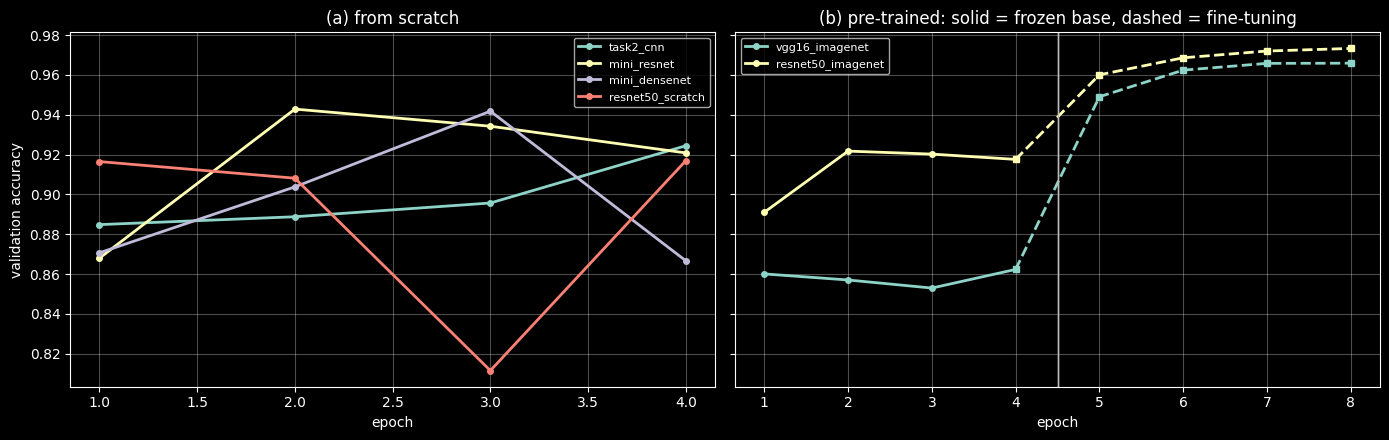

In [8]:
# 3) Learning curves (validation accuracy per epoch). Fine-tuning continues the feature-extraction curve.
hs = json.loads(HISTORY_JSON.read_text())
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for name in [c for c in res.config if res.set_index("config").loc[c, "part"] == "a"]:
    v = hs[name]["val_accuracy"]
    axes[0].plot(range(1, len(v) + 1), v, marker="o", ms=4, lw=2, label=name)
axes[0].set_title("(a) from scratch"); axes[0].set_xlabel("epoch"); axes[0].set_ylabel("validation accuracy")
for name in [c for c in res.config if c.endswith("_feature_extract")]:
    fe = hs[name]["val_accuracy"]
    ft = hs.get(name.replace("_feature_extract", "_fine_tune"), {}).get("val_accuracy", [])
    line, = axes[1].plot(range(1, len(fe) + 1), fe, marker="o", ms=4, lw=2,
                         label=name.replace("_feature_extract", ""))
    if ft:
        axes[1].plot(range(len(fe), len(fe) + len(ft) + 1), [fe[-1]] + ft, marker="s", ms=4, lw=2,
                     ls="--", color=line.get_color())
        axes[1].axvline(len(fe) + 0.5, color="#bbb", lw=1)
axes[1].set_title("(b) pre-trained: solid = frozen base, dashed = fine-tuning")
axes[1].set_xlabel("epoch")
for ax in axes: ax.legend(fontsize=8); ax.grid(alpha=0.3)
plt.tight_layout(); fig.savefig(plots / "learning_curves.png", dpi=150); plt.show()

# Discussion

**Questions the table should answer:**
1. **Does architecture alone help?** Compare `mini_resnet` and `mini_densenet` with `task2_cnn`.
   They are in the same size class (1–2.4M parameters), so any gain mostly comes from the design: skip
   connections, feature reuse, BatchNorm.
2. **Does sheer size help?** Compare `resnet50_scratch` (about 24M parameters) with the small
   models. Bigger isn't automatically better in 4 epochs: big models from scratch are slow to train.
3. **What is pre-training worth?** Compare `resnet50_scratch` with `resnet50_imagenet_*`. The
   architecture is identical and only the starting weights differ.
4. **What does fine-tuning add on top of frozen features?** Compare `*_feature_extract` with
   `*_fine_tune`.
5. **Cost:** read `sec_per_epoch` and `cumulative_train_sec` beside the accuracy. A model that is
   1% better but 20× slower is a trade-off worth naming.

**Why pre-training might help less than usual here.** ImageNet features were learned to
recognize *objects*: edges, textures, parts, whole things. Real vs. fake isn't an object question,
since both classes contain the same kinds of objects. The difference is in pixel-level
statistics. The early pre-trained layers (edge and texture detectors) are general enough to
transfer, but the deep layers are tuned to object categories. That predicts the frozen base will
do relatively poorly, and that **fine-tuning will matter a lot**, because it is what lets the
deep layers re-tune to this task. If the results show that pattern, it is a strong point for the
report.

*Fill in your observations here once the run finishes.*